In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
from itertools import product
from collections import Counter
import os
from Bio.Seq import reverse_complement
from Bio import SeqIO



In [5]:
genome_dir = "../bvbrc_fna/"

genomes = {}
for fn in sorted(os.listdir(genome_dir)):
    if fn.endswith((".fna", ".fasta", ".fa")):
        gid = fn.rsplit(".", 1)[0]    
        genomes[gid] = "".join(str(r.seq) for r in SeqIO.parse(os.path.join(genome_dir, fn), "fasta"))

print(f"reloaded {len(genomes)} genomes")

reloaded 929 genomes


In [17]:
if not genomes:
    raise RuntimeError("No genomes loaded — check the genome_folder path")

lengths = [len(s) for s in genomes.values()]
print(f"\nGenome length: min={min(lengths):,}  max={max(lengths):,}  "
      f"mean={np.mean(lengths):,.0f}  median={np.median(lengths):,.0f}")

SHORT_THRESHOLD = 1_000_000
short = {g: len(s) for g, s in genomes.items() if len(s) < SHORT_THRESHOLD}
if short:
    print(f"\n  {len(short)} genomes under {SHORT_THRESHOLD:,} bp:")
    for g, n in short.items():
        print(f"  {g}: {n:,} bp")
    # Drop them
    genomes = {g: s for g, s in genomes.items() if len(s) >= SHORT_THRESHOLD}

print("\nN content (first 5):")
for gid, seq in list(genomes.items())[:5]:
    n_pct = (seq.count("N") / len(seq)) * 100
    print(f"  {gid}: {n_pct:.2f}% N")


Genome length: min=5,631  max=5,855,691  mean=1,440,459  median=995,434

  466 genomes under 1,000,000 bp:
  1050617.35: 69,065 bp
  1055537.35: 878,973 bp
  1055537.42: 677,705 bp
  1116063.3: 949,125 bp
  1125646.3: 643,812 bp
  1126911.3: 714,962 bp
  1317131.3: 292,123 bp
  1333594.3: 857,628 bp
  1355101.18: 5,631 bp
  1370107.3: 340,621 bp
  1392869.9: 88,206 bp
  1444110.3: 605,016 bp
  1444258.3: 668,931 bp
  1446601.3: 891,629 bp
  244319.287: 468,866 bp
  244319.31: 394,209 bp
  409438.53: 60,555 bp
  562.100034: 705,277 bp
  562.100054: 819,464 bp
  562.100064: 626,977 bp
  562.100284: 814,995 bp
  562.100324: 706,151 bp
  562.10066: 704,460 bp
  562.100763: 815,492 bp
  562.100929: 955,027 bp
  562.101977: 484,744 bp
  562.102005: 112,316 bp
  562.102494: 622,762 bp
  562.103971: 129,408 bp
  562.10501: 669,184 bp
  562.106131: 699,624 bp
  562.106152: 754,126 bp
  562.106326: 862,477 bp
  562.107185: 375,274 bp
  562.107737: 995,434 bp
  562.108402: 616,448 bp
  562.10867

In [18]:
len(genomes)

463

In [19]:
def get_all_kmers(k):
    # Generate all possible k-mers for DNA alphabet.
    # This defines the fixed vocabulary — every genome gets score against the same list, even if some k-mers never appear
    bases = ['A', 'C', 'G', 'T']
    return [''.join(p) for p in product(bases, repeat=k)]

In [20]:
def count_kmers(sequence, k=4, include_reverse_complement=True):
    """
    Count k-mer frequencies in a DNA sequence.

    Parameters:
        sequence: DNA string (uppercase)
        k: k-mer length
        include_reverse_complement: if True, also count the reverse strand

    Returns:
        dict mapping each possible k-mer to its relative frequency
    """

    # Remove N and any non-ATGC characters
    sequence = sequence.upper()
    sequence = ''.join(b for b in sequence if b in 'ATGC')

    if len(sequence) < k:
        raise ValueError(f'Sequence too short ({len(sequence)} bp for k={k}')

    # Build the complete vocabulary (all 4^k possible k-mers)
    vocabulary = get_all_kmers(k)
    counts = Counter({kmer: 0 for kmer in vocabulary})  # start all at 0

    # Count k-mers on the forward strand
    for i in range(len(sequence) - k + 1):
        kmer = sequence[i : i+k]
        if kmer in counts:
            counts[kmer] += 1
    
    # Count reverse complement strand too
    if include_reverse_complement:
        rev_comp = reverse_complement(sequence)
        for i in range(len(rev_comp) - k + 1):
            kmer = rev_comp[i : i+k]
            if kmer in counts:
                counts[kmer] += 1
    
    # Convert to relative frequencies
    total = sum(counts.values())
    frequencies = {kmer: counts[kmer] / total for kmer in vocabulary}
    
    return frequencies


In [21]:
def reverse_complement(sequence):
    # Return the reverse complement of a DNA sequence
    complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G'}
    return ''.join(complement[b] for b in reversed(sequence))


In [10]:
# Test
test_seq = "ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG"
freqs = count_kmers(test_seq, k=4)

print(f"Total k-mers in vocabulary: {len(freqs)}")
print(f"All frequencies sum to: {sum(freqs.values()):.6f}")

Total k-mers in vocabulary: 256
All frequencies sum to: 1.000000


In [12]:
test_genome = list(genomes.values())[0]
print(f'Genome length: {len(test_genome):,}bp/n ')

for k in [3, 4, 5, 6]:
    start = time.time()
    freqs = count_kmers(test_genome, k=k)
    elapsed = time.time() - start
    print(f'k={k}: {len(freqs):>5} features, computed in {elapsed: .2f}')

Genome length: 4,983,288bp/n 
k=3:    64 features, computed in  3.51
k=4:   256 features, computed in  3.52
k=5:  1024 features, computed in  3.75
k=6:  4096 features, computed in  3.86


In [22]:
from itertools import islice

# Peek at just 5 keys
sample_keys = list(islice(genomes.keys(), 5))
print("Sample keys:", sample_keys)

# Peek at key + value type and length/shape
for k, v in islice(genomes.items(), 5):
    size = len(v) if hasattr(v, "__len__") else "n/a"
    print(f"{k!r}: type={type(v).__name__}, len={size}")

Sample keys: ['1004153.3', '1038927.41', '1116012.3', '1116177.3', '1144303.3']
'1004153.3': type=str, len=4983288
'1038927.41': type=str, len=5500653
'1116012.3': type=str, len=1048114
'1116177.3': type=str, len=1436136
'1144303.3': type=str, len=3020270


In [23]:
first_key = next(iter(genomes))
val = genomes[first_key]
print("First key:", first_key)
print("Preview:", val[:100] if isinstance(val, (str, bytes, list, tuple)) else val)

First key: 1004153.3
Preview: tgcgccgtcagggaaggaaggtaccgcattcatggcgctgatggcagaaaaagcccggcttgctgccctgctgccggatgaatgggaacgggacatgacg


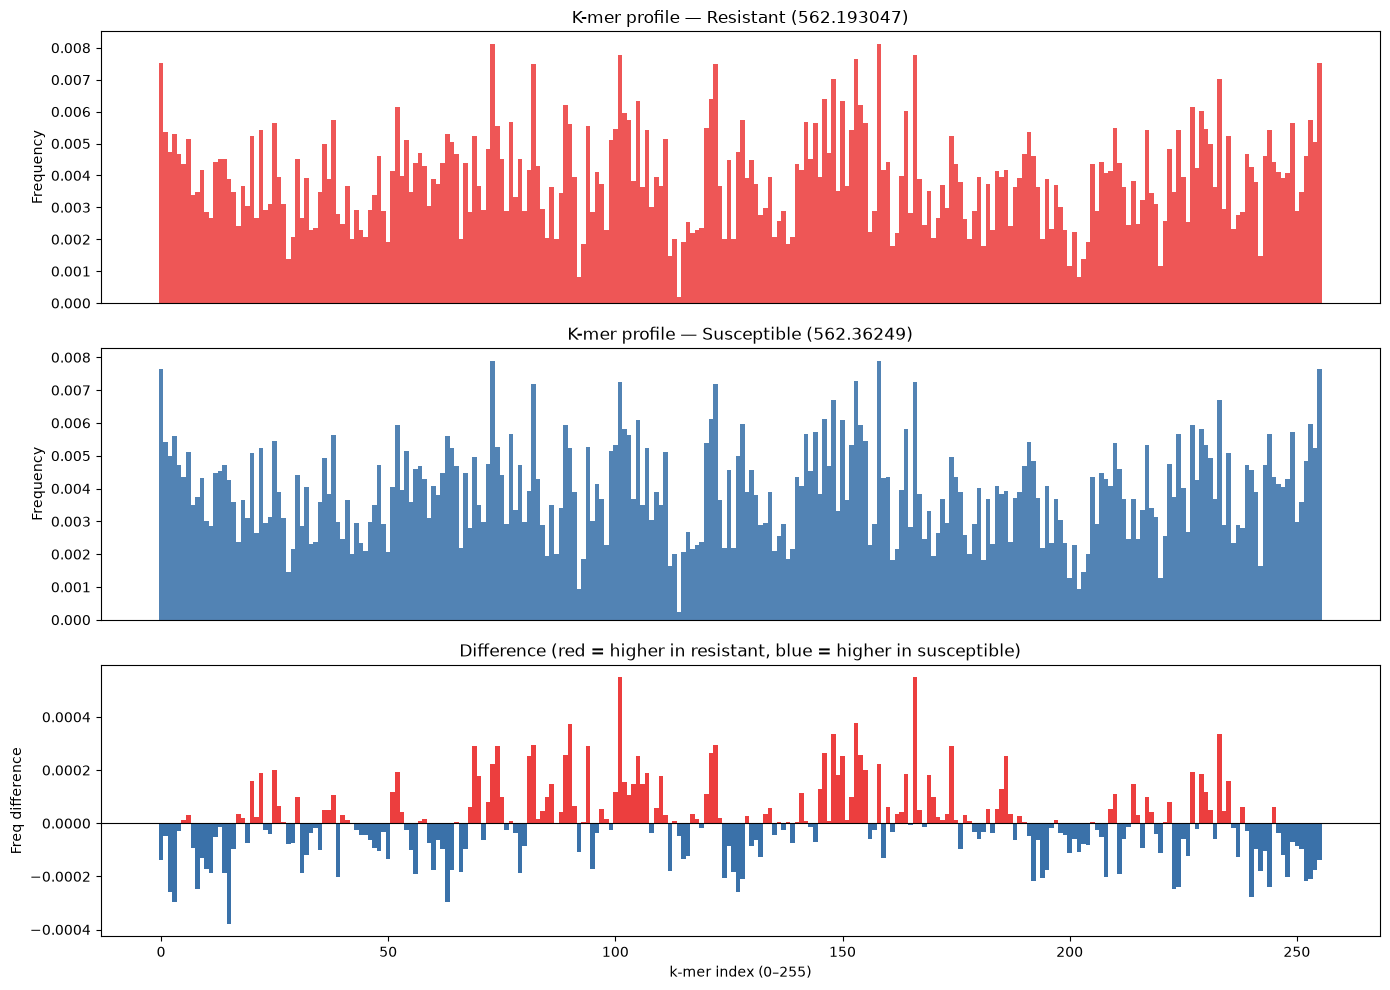


Top 10 most different k-mers between these two genomes:
  GGCG  diff=+0.00055
  CGCC  diff=+0.00055
  AATT  diff=-0.00038
  GCGC  diff=+0.00038
  CCGG  diff=+0.00037
  TGGC  diff=+0.00033
  GCCA  diff=+0.00033
  ATTT  diff=-0.00030
  AAAT  diff=-0.00030
  CCAG  diff=+0.00030


In [25]:
labels_df = pd.read_csv("../data/cleaned.csv", low_memory=False)

# Find one resistant and one susceptible genome ID
resistant_id = labels_df[labels_df["label"] == 1]["Genome ID"].iloc[0]
susceptible_id = labels_df[labels_df["label"] == 0]["Genome ID"].iloc[0]

k = 4
vocab = get_all_kmers(k)

r_freqs = count_kmers(genomes[str(resistant_id)], k=k)
s_freqs = count_kmers(genomes[str(susceptible_id)], k=k)

r_vals = [r_freqs[km] for km in vocab]
s_vals = [s_freqs[km] for km in vocab]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Panel 1: resistant profile
axes[0].bar(range(len(vocab)), r_vals, color="#E80E0E", alpha=0.7, width=1.0)
axes[0].set_title(f"K-mer profile — Resistant ({resistant_id})")
axes[0].set_ylabel("Frequency")
axes[0].set_xticks([])

# panel 2: susceptible profile
axes[1].bar(range(len(vocab)), s_vals, color="#084E94", alpha=0.7, width=1.0)
axes[1].set_title(f"K-mer profile — Susceptible ({susceptible_id})")
axes[1].set_ylabel("Frequency")
axes[1].set_xticks([])

# Panel 3: difference (which k-mers differ between the two)
diff = np.array(r_vals) - np.array(s_vals)
colors = ["#E80E0E" if d > 0 else "#084E94" for d in diff]
axes[2].bar(range(len(vocab)), diff, color=colors, alpha=0.8, width=1.0)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_title("Difference (red = higher in resistant, blue = higher in susceptible)")
axes[2].set_ylabel("Freq difference")
axes[2].set_xlabel("k-mer index (0–255)")

plt.tight_layout()
plt.savefig("../plots/kmer_profiles_comparison.png", dpi=500, bbox_inches='tight')
plt.show()

# Find the most discriminating k-mers
top_diff_indices = np.argsort(np.abs(diff))[-10:][::-1]
print("\nTop 10 most different k-mers between these two genomes:")
for idx in top_diff_indices:
    print(f"  {vocab[idx]}  diff={diff[idx]:+.5f}")


In [26]:
# Compute kmer frequency
k = 4
vocab = get_all_kmers(k)
all_features = {}
errors = []

print(f"Computing {k}-mer frequencies for {len(genomes)} genomes...\n")
start_total = time.time()

for i, (genome_id, sequence) in enumerate(genomes.items()):
    try:
        freqs = count_kmers(sequence, k=k)
        all_features[genome_id] = [freqs[km] for km in vocab]
        
        if (i + 1) % 10 == 0:
            elapsed = time.time() - start_total
            print(f"  {i+1}/{len(genomes)} done  ({elapsed:.1f}s elapsed)")
    
    except Exception as e:
        print(f"  ERROR on {genome_id}: {e}")
        errors.append(genome_id)

print(f"\nDone. {len(all_features)} succeeded, {len(errors)} failed.")
if errors:
    print(f"Failed genomes: {errors}")



Computing 4-mer frequencies for 463 genomes...

  10/463 done  (22.7s elapsed)
  20/463 done  (44.5s elapsed)
  30/463 done  (58.4s elapsed)
  40/463 done  (73.7s elapsed)
  50/463 done  (85.3s elapsed)
  60/463 done  (100.9s elapsed)
  70/463 done  (122.5s elapsed)
  80/463 done  (141.5s elapsed)
  90/463 done  (160.4s elapsed)
  100/463 done  (184.0s elapsed)
  110/463 done  (209.6s elapsed)
  120/463 done  (218.2s elapsed)
  130/463 done  (229.8s elapsed)
  140/463 done  (242.6s elapsed)
  150/463 done  (269.9s elapsed)
  160/463 done  (281.5s elapsed)
  170/463 done  (291.3s elapsed)
  180/463 done  (307.4s elapsed)
  190/463 done  (327.6s elapsed)
  200/463 done  (338.1s elapsed)
  210/463 done  (359.3s elapsed)
  220/463 done  (381.2s elapsed)
  230/463 done  (394.6s elapsed)
  240/463 done  (405.3s elapsed)
  250/463 done  (416.8s elapsed)
  260/463 done  (427.0s elapsed)
  270/463 done  (444.9s elapsed)
  280/463 done  (464.7s elapsed)
  290/463 done  (476.9s elapsed)
  300/463

In [27]:
# Save feature matrix and vocabulary
feature_ids = list(all_features.keys())

# Build the numpy array
feature_matrix = np.array([all_features[gid] for gid in feature_ids])

np.save('../features/kmer_matrix.npy', feature_matrix)

with open('../features/kmer_metadata.json', 'w') as f:
    json.dump({"genome_ids": feature_ids, "vocab": vocab, "k": k}, f)


print(f"Saved feature matrix: {feature_matrix.shape}")
print(f"  Rows = genomes: {feature_matrix.shape[0]}")
print(f"  Cols = k-mers:  {feature_matrix.shape[1]}")

Saved feature matrix: (463, 256)
  Rows = genomes: 463
  Cols = k-mers:  256


In [28]:
label_ids = set(labels_df["Genome ID"].astype(str))

# Find shared genomes
feature_ids_set = set(feature_ids)
shared_ids = feature_ids_set & label_ids


In [29]:
# Order the genomes
sorted_ids = sorted(shared_ids)
print(f"Building matrix from {len(sorted_ids)} genomes")

id_to_row_index = {                            
    genome_id: i for i, genome_id in enumerate(feature_ids)
}
sorted_row_indices = [id_to_row_index[g] for g in sorted_ids]

X = feature_matrix[sorted_row_indices].astype(np.float32)

label_lookup = labels_df.set_index("Genome ID")["label"]
label_lookup.index = label_lookup.index.astype(str)

y_vals = []
for genome_id in sorted_ids:
    val = label_lookup.loc[genome_id]

    if isinstance(val, pd.Series):
        y_vals.append(val.iloc[0])
    else:
        y_vals.append(val)

y = np.array(y_vals, dtype=np.int32)

print(f"\nX shape: {X.shape}  (rows=genomes, cols=k-mers)")
print(f"y shape: {y.shape}")

unique_classes, counts = np.unique(y, return_counts=True)
print(f"y values breakdown: {dict(zip(unique_classes, counts))}")

Building matrix from 463 genomes

X shape: (463, 256)  (rows=genomes, cols=k-mers)
y shape: (463,)
y values breakdown: {np.int32(0): np.int64(337), np.int32(1): np.int64(126)}


In [30]:
print("Alignment spot check\n")
print(f"{'Index':<6} {'Genome ID':<25} {'Label':<10} {'Feature sum':<15} {'First 3 features'}")
print("-" * 75)

for i in [0, 1, 2, -3, -2, -1]:  # checking first 3 and last 3
    gid = sorted_ids[i]
    label = y[i]
    feat_sum = X[i].sum()
    first3 = X[i][:3].round(5)
    print(f"{i:<6} {gid:<25} {label:<10} {feat_sum:<15.6f} {first3}")

#  Relative frequencies
row_sums = X.sum(axis=1)
print(f"\nRow sum stats (should all be ~1.0):")
print(f"  Min: {row_sums.min():.6f}")
print(f"  Max: {row_sums.max():.6f}")
print(f"  Mean: {row_sums.mean():.6f}")

Alignment spot check

Index  Genome ID                 Label      Feature sum     First 3 features
---------------------------------------------------------------------------
0      1004153.3                 0          1.000000        [0.00768 0.00542 0.00494]
1      1038927.41                0          1.000000        [0.00775 0.00536 0.00493]
2      1116012.3                 0          1.000000        [0.00791 0.00547 0.00504]
-3     83334.614                 0          1.000000        [0.00803 0.00536 0.00492]
-2     83334.673                 0          1.000000        [0.00801 0.00537 0.00494]
-1     868178.3                  0          1.000000        [0.00784 0.00539 0.00494]

Row sum stats (should all be ~1.0):
  Min: 1.000000
  Max: 1.000000
  Mean: 1.000000


Resistant:   126 (27.2%)
Susceptible: 337 (72.8%)


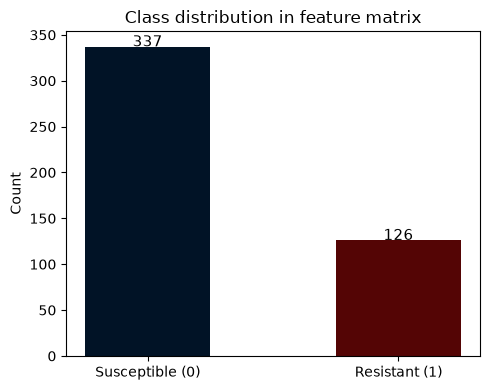

In [31]:
n_resistant   = (y == 1).sum()
n_susceptible = (y == 0).sum()
total = len(y)

print(f"Resistant:   {n_resistant} ({n_resistant/total:.1%})")
print(f"Susceptible: {n_susceptible} ({n_susceptible/total:.1%})")

# Visualization
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Susceptible (0)", "Resistant (1)"],
              [n_susceptible, n_resistant],
              color=["#011326", "#540505"], width=0.5)

for bar, count in zip(bars, [n_susceptible, n_resistant]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            str(count), ha="center", fontsize=11)

ax.set_title("Class distribution in feature matrix")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig('../plots/class_distribution.png', dpi=500, bbox_inches = 'tight')
plt.show()

# Flag imbalance
ratio = min(n_resistant, n_susceptible) / max(n_resistant, n_susceptible)
if ratio < 0.5:
    print(f"\nWARNING: imbalanced classes (ratio={ratio:.2f})")
else:
    print(f"\nClass balance OK (ratio={ratio:.2f})")

In [32]:
# Build a labelled DataFrame 
vocab = get_all_kmers(4)  # k-mer column names

df_features = pd.DataFrame(X, columns=vocab, index=sorted_ids)
df_features.index.name = "genome_id"
df_features["label"] = y

print(df_features.shape)
print(df_features.head(3))

# Do resistant genomes have different mean k-mer profiles?
r_means = df_features[df_features["label"] == 1].drop("label", axis=1).mean()
s_means = df_features[df_features["label"] == 0].drop("label", axis=1).mean()

diff = (r_means - s_means).abs().sort_values(ascending=False)
print(f"\nTop 10 k-mers with biggest mean difference between classes:")
print(diff.head(10))

(463, 257)
                AAAA      AAAC      AAAG      AAAT      AACA      AACC  \
genome_id                                                                
1004153.3   0.007677  0.005422  0.004939  0.005555  0.004776  0.004363   
1038927.41  0.007751  0.005361  0.004930  0.005578  0.004735  0.004335   
1116012.3   0.007914  0.005470  0.005038  0.005796  0.004669  0.004437   

                AACG      AACT      AAGA      AAGC  ...      TTCT      TTGA  \
genome_id                                           ...                       
1004153.3   0.005218  0.003447  0.003637  0.004202  ...  0.004054  0.004129   
1038927.41  0.005052  0.003458  0.003672  0.004202  ...  0.004112  0.004120   
1116012.3   0.005162  0.003424  0.003760  0.004302  ...  0.004043  0.004244   

                TTGC      TTGG      TTGT      TTTA      TTTC      TTTG  \
genome_id                                                                
1004153.3   0.005796  0.002892  0.003611  0.004794  0.005967  0.005155   


In [33]:

# Save X and y as numpy arrays
np.save("../features/X.npy", X)
np.save("../features/y.npy", y)

# Save the genome ID order — critical for tracing predictions back to genomes
with open("../features/genome_order.txt", "w") as f:
    for gid in sorted_ids:
        f.write(gid + "\n")

# Save the full labelled DataFrame as CSV for easy inspection
df_features.to_csv("../features/feature_matrix.csv")

# Visualization
print("Saved:")
print(f"  features/X.npy          {X.shape}")
print(f"  features/y.npy          {y.shape}")
print(f"  features/genome_order.txt  {len(sorted_ids)} IDs")
print(f"  features/feature_matrix.csv")

Saved:
  features/X.npy          (463, 256)
  features/y.npy          (463,)
  features/genome_order.txt  463 IDs
  features/feature_matrix.csv
